In [ ]:
import sys
!{sys.executable} -m pip install scvi-tools scikit-misc

In [ ]:
import scanpy as sc
import scvi
from google.colab import drive

drive.mount('/content/drive')
adata = sc.read_h5ad('/content/drive/MyDrive/tumor/preprocessed.h5ad')

scvi.model.SCVI.setup_anndata(adata, layer='counts', batch_key='sample')
model = scvi.model.SCVI(adata)
model.train() 

adata.obsm['X_scVI'] = model.get_latent_representation()

adata.write('/content/drive/MyDrive/tumor/integrated30.h5ad')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespe

Training:   0%|          | 0/23 [00:00<?, ?it/s]

In [ ]:
import scanpy as sc
import scvi
from google.colab import drive

drive.mount('/content/drive')
adata = sc.read_h5ad('/content/drive/MyDrive/tumor/integrated.h5ad')

adata.obsm['X_scVI_10'] = adata.obsm['X_scVI'].copy()

scvi.model.SCVI.setup_anndata(adata, layer='counts', batch_key='sample')
model = scvi.model.SCVI(adata, n_latent=30)
model.train() 

adata.obsm['X_scVI_30'] = model.get_latent_representation()

model.save('/content/drive/MyDrive/tumor/scvi_n30', overwrite=True)
adata.write('/content/drive/MyDrive/tumor/integrated.h5ad')

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: You are using a CUDA device ('NVIDIA A100-SXM4-80GB') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For m

Training:   0%|          | 0/23 [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_epochs=23` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=23` reached.


In [ ]:
adata.obsm

AxisArrays with keys: 'X_scVI', 'X_scVI_10', 'X_scVI_30'

In [ ]:
sc.pp.neighbors(adata, use_rep='X_scVI_30', n_neighbors=30)
sc.tl.umap(adata)

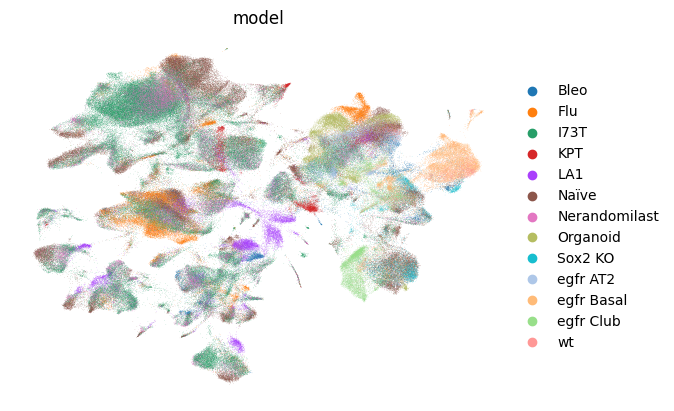

In [ ]:
sc.pl.umap(adata, color='model', frameon=False)

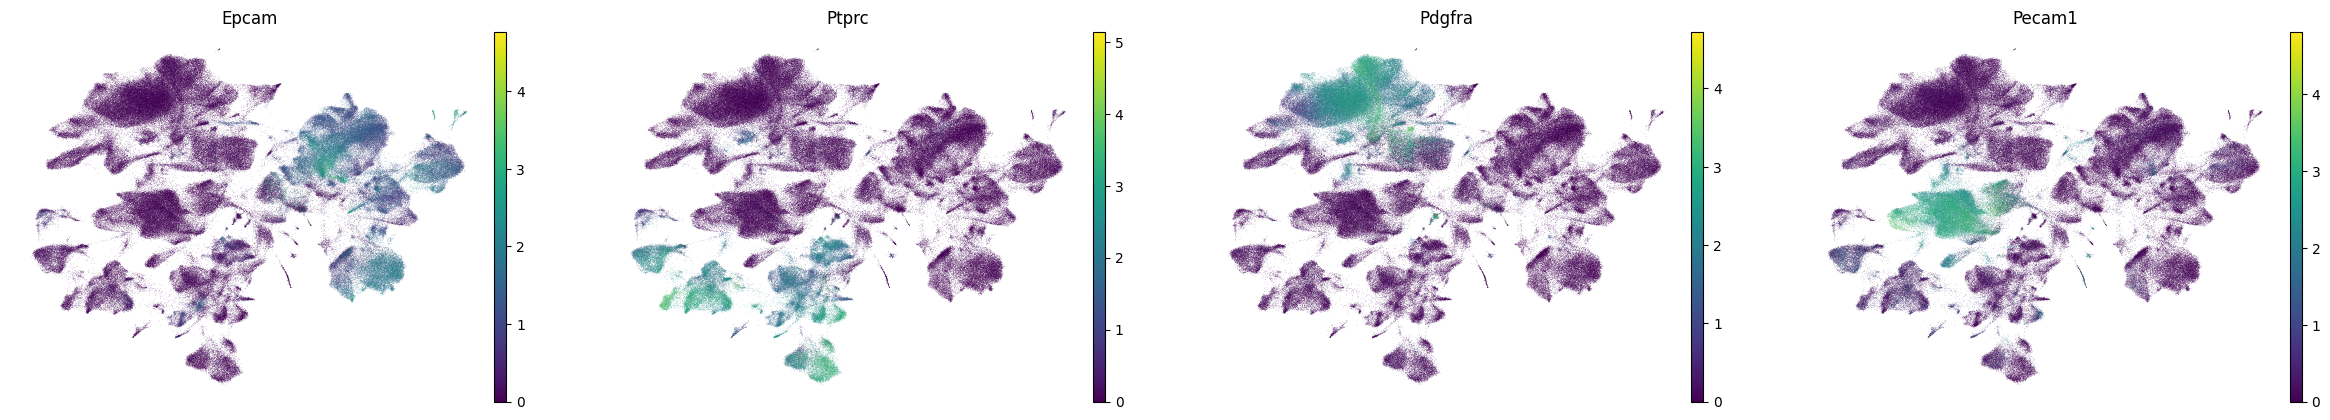

In [ ]:
sc.pl.umap(adata, color=['Epcam', 'Ptprc', 'Pdgfra', 'Pecam1'], frameon=False)

In [ ]:
adata.write_h5ad('integrated30.h5ad')

In [ ]:
del adata.obsm['X_scVI']

In [ ]:
adata.obsm

AxisArrays with keys: 'X_scVI_10', 'X_scVI_30', 'X_umap'

In [ ]:
scvi.model.SCVI.setup_anndata(adata, layer='counts', batch_key='sample')
model = scvi.model.SCVI(adata, n_latent=20)
model.train() 

adata.obsm['X_scVI_20'] = model.get_latent_representation()

model.save('/content/drive/MyDrive/tumor/scvi_n20', overwrite=True)
adata.write('/content/drive/MyDrive/tumor/integrated.h5ad')

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespe

Training:   0%|          | 0/23 [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_epochs=23` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=23` reached.


In [ ]:
adata.obsm

AxisArrays with keys: 'X_scVI_10', 'X_scVI_30', 'X_umap', 'X_scVI_20'

In [ ]:
sc.pp.neighbors(adata, use_rep='X_scVI_20', n_neighbors=30)
sc.tl.umap(adata)

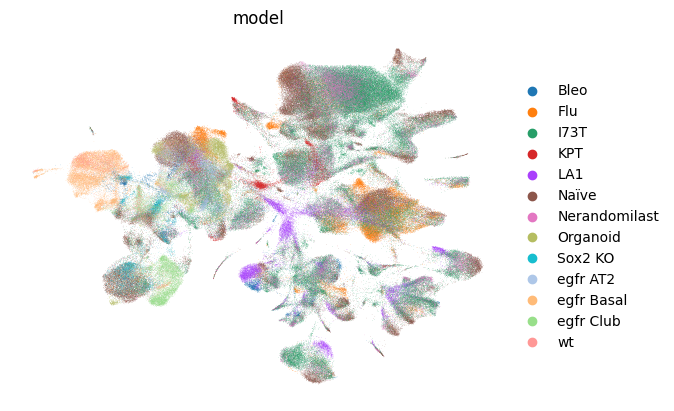

In [ ]:
sc.pl.umap(adata, color='model', frameon=False)